# Final plots — Netherlands showcase

The figures meant to actually represent this case in the **GUI results
portal** ("Final Plots" tab) — trimmed down to what's genuinely useful for
understanding it, not a full slide deck. Last step in the pipeline, after
validation (09-11).

**Story arc**
1. Domain — satellite + bathymetry + isobaths, AoI, the full mesh, and
   goals/sectors (no buoy — it only added noise here)
2. Reconstruction comparison — dynamic SnapWave vs. the metamodel, for a
   stormy moment and a calm moment, at every isobath + buoy site
3. Metamodel training — sampled SnapWave LHS cases per goal (notebook 05)
4. Reconstruction spectra network — spectra bubbles along the 5 m isobath +
   forcing arrows, for one moment

**Outputs:** `outputs/gui_figures/*.png`, shown by the GUI ("Final Plots" tab).

**Prerequisites:** goals GPKG, WHACS zarr, SnapWave LHS cases, fitted
models, the mesh netCDF (`inputs/GRID/`), a consolidated dynamic-hindcast
file (`Dynamic_Cases_WHACS_<comparison_period>.nc` — only 2010 and 2017
exist for this case, see the config cell), and reconstruction spectra
caches for `period` (notebooks 05-08, 11).


In [1]:
import os
import sys

# Must run before any GDAL-touching import (geopandas/pyogrio, rasterio/rioxarray).
# When the kernel is launched without going through `conda activate` (e.g. VS
# Code's Jupyter extension), GDAL_DATA/PROJ_DATA are unset, and importing
# rioxarray/rasterio before geopandas.read_file() in that state leaves GDAL's
# data-path auto-discovery broken for pyogrio, raising:
#   ValueError: Found GDAL data directory at .../share/gdal but it does not
#   appear to correctly contain GDAL data files
# Setting these explicitly sidesteps the broken auto-discovery.
os.environ.setdefault("GDAL_DATA", os.path.join(sys.prefix, "share", "gdal"))
os.environ.setdefault("PROJ_DATA", os.path.join(sys.prefix, "share", "proj"))

from pathlib import Path

import cartopy.crs as ccrs
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from bluemath_tk.core.plotting.spectra import render_spectrum_bubble
from bluemath_tk.waves.hywaves.plots import goal_colors
from IPython.display import display
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
from utils import metamodel as mm
from utils import onshore_sites as obs
from utils import validation as val
from utils import viz as cp
from utils.config import (
    PATHS,
    SIMULATIONS,
    goals_for_snapwave,
    load_goals,
    open_offshore_waves,
    resolve,
)
from utils.geometry import site_meta
from utils.simulation import HyWavesWrapperSetup, cases_dir

## Configuration & helpers


In [ ]:
# --- slide / export settings ---
EXPORT_DIR = resolve("outputs/gui_figures")
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
DPI = 200
FIGSIZE_WIDE = (13.33, 7.5)  # 16:9
FIGSIZE_TALL = (10.0, 11.0)

# --- case study ---
# period/buoy match the combination already confirmed to have working
# reconstruction spectra caches in 11_Validate_Spectra.ipynb.
period = "2013"
forcing_moment = None  # None -> storm peak at buoy goal
offshore_name = "WHACS_cal"
mda_n = 550
wl = "forcing"

buoy_instrument = "AmelanderZeegat_1_1"  # instrument_id from the observations GeoJSON
buoy_site = obs.snapwave_site_id(buoy_instrument)

# The dynamic-vs-metamodel comparison figure needs a consolidated dynamic
# hindcast file (Dynamic_Cases_WHACS_<year>.nc) — only 2010 and 2017 exist
# for this case (not `period` above, which is 2011 and only has spectra
# reconstruction caches, no consolidated dynamic file). Kept as its own
# variable rather than reusing `period` so this doesn't silently break if
# `period` ever changes.
comparison_period = "2013"
dynamic_path = (
    cases_dir("dynamic") / f"Dynamic_Cases_{offshore_name}_{comparison_period}.nc"
)

GOALS_GPKG = resolve(SIMULATIONS["goals_file"]).with_suffix(".gpkg")
goals = load_goals()
goals_config = goals_for_snapwave(goals)
targets = gpd.read_file(GOALS_GPKG, layer="targets")
boundary_snaps_gdf = gpd.read_file(GOALS_GPKG, layer="boundary_snaps")
boundary_snaps = {
    str(int(row.goal_id)): {
        "longitude": float(row.geometry.x),
        "latitude": float(row.geometry.y),
    }
    for _, row in boundary_snaps_gdf.iterrows()
}

case_setup = HyWavesWrapperSetup.from_case(goals)
aoi_gdf = case_setup.aoi_gdf
model_boundary, model_boundary_label = case_setup.model_boundary
output_sites_df = case_setup.output_sites_df

goal_map = val.closest_goals_table([buoy_site], offshore_names=[offshore_name])
buoy_goal = int(goal_map.goal.iloc[0])
print(f"Export dir       : {EXPORT_DIR}")
print(f"Period           : {period}")
print(f"Comparison period: {comparison_period}  (dynamic ref: {dynamic_path.name})")
print(f"Buoy site        : {buoy_site}  ->  closest goal G{buoy_goal}")


def apply_slide_style() -> None:
    plt.rcParams.update(
        {
            "font.size": 13,
            "axes.titlesize": 15,
            "axes.labelsize": 13,
            "legend.fontsize": 11,
            "figure.facecolor": "white",
            "savefig.facecolor": "white",
        }
    )


def save_fig(fig, name: str) -> Path:
    path = EXPORT_DIR / f"{name}.png"
    fig.savefig(path, dpi=DPI, bbox_inches="tight", facecolor="white")
    display(fig)  # renders inline here, and in the Jupyter Book build
    plt.close(fig)
    print(f"saved -> {path}")
    return path


def build_lhs_cases_df() -> pd.DataFrame:
    """Forcing table from the model LHS NetCDFs (one file per goal)."""
    chunks: list[pd.DataFrame] = []
    for gid in sorted(goals, key=int):
        with xr.open_dataset(mm.cases_path(gid)) as ds:
            df = ds[[f"{v}_forcing" for v in mm.MDA_INPUTS]].to_dataframe()
        df.columns = mm.MDA_INPUTS
        df.insert(0, "goal", int(gid))
        chunks.append(df.reset_index(drop=True))
    return pd.concat(chunks, ignore_index=True)


def pick_storm_peak_time(goal_id: int, *, period_: str | None = None) -> pd.Timestamp:
    off = open_offshore_waves(offshore_name).sel(time=period_ or period, goal=goal_id)
    return pd.Timestamp(off["hs"].idxmax("time").values)


def pick_calm_time(goal_id: int, *, period_: str | None = None) -> pd.Timestamp:
    """Lowest-Hs moment in the offshore series — the "calm day" counterpart to
    :func:`pick_storm_peak_time`, for the reconstruction comparison figure."""
    off = open_offshore_waves(offshore_name).sel(time=period_ or period, goal=goal_id)
    return pd.Timestamp(off["hs"].idxmin("time").values)


apply_slide_style()

PARTITION_STYLE = {
    0: ("Wind sea (p0)", "#e41a1c"),
    1: ("Swell 1 (p1)", "#377eb8"),
    2: ("Swell 2 (p2)", "#4daf4a"),
    3: ("Swell 3 (p3)", "#984ea3"),
}


def resolve_forcing_moment(goal_id: int | None = None) -> pd.Timestamp:
    if forcing_moment is not None:
        return pd.Timestamp(forcing_moment)
    gid = buoy_goal if goal_id is None else goal_id
    return pick_storm_peak_time(gid)


def offshore_partitions_at(time: pd.Timestamp) -> xr.Dataset:
    return open_offshore_waves(offshore_name).sel(time=time, method="nearest")


def _partition_arrowprops(
    lon: float,
    lat: float,
    dir_deg: float,
    *,
    scale_deg: float,
    color: str,
    lw: float = 2.4,
    alpha: float = 0.92,
):
    """Arrow style with larger heads for course maps."""
    theta = np.deg2rad(float(dir_deg))
    dlon = np.sin(theta) * scale_deg
    dlat = np.cos(theta) * scale_deg
    return (
        dict(
            arrowstyle="-|>",
            color=color,
            lw=lw,
            alpha=alpha,
            shrinkA=0,
            shrinkB=2,
            mutation_scale=16,
        ),
        (lon + dlon, lat + dlat),
        (lon, lat),
    )


def course_map_extent(
    *, pad_lon: float = 0.15, pad_lat: float = 0.12
) -> tuple[float, float, float, float]:
    """Lon/lat limits that include AoI, all goals, WHACS nodes, and buoy."""
    lons: list[float] = []
    lats: list[float] = []
    for g in goals.values():
        lons.append(g["target"]["longitude"])
        lats.append(g["target"]["latitude"])
        hc = g["hindcast"]["whacs"]
        lons.append(hc["longitude"])
        lats.append(hc["latitude"])
    for snap in boundary_snaps.values():
        lons.append(snap["longitude"])
        lats.append(snap["latitude"])
    buoy = obs.get_coordinates()[buoy_instrument]
    lons.append(buoy["lon"])
    lats.append(buoy["lat"])
    bb = aoi_gdf.total_bounds
    lons.extend([float(bb[0]), float(bb[2])])
    lats.extend([float(bb[1]), float(bb[3])])
    return (
        min(lons) - pad_lon,
        max(lons) + pad_lon,
        min(lats) - pad_lat,
        max(lats) + pad_lat,
    )


def partition_legend_handles() -> list:
    """Legend entries with arrow glyphs for partition colours."""
    handles = []
    for part, (label, color) in sorted(PARTITION_STYLE.items()):
        handles.append(
            plt.Line2D(
                [0],
                [0],
                color=color,
                linewidth=3.2,
                marker=">",
                markersize=11,
                markeredgewidth=0,
                label=f"{label}  (dir = wave-from, len ∝ Hs)",
            )
        )
    handles.append(
        plt.Line2D(
            [0],
            [0],
            marker="o",
            color="w",
            markerfacecolor="black",
            markersize=7,
            linestyle="None",
            label="goal boundary snap",
        )
    )
    return handles


def draw_goal_partition_arrows(
    ax,
    time: pd.Timestamp,
    *,
    arrow_base_deg: float = 0.30,
    hs_floor: float = 0.04,
    fan_offset_deg: float = 0.028,
) -> None:
    """Four partition arrows per goal (wave-from direction, length ∝ phs)."""
    off = offshore_partitions_at(time)
    goal_ids = sorted(int(g) for g in off.goal.values)
    part_vars = [f"phs{i}" for i in range(4)]
    hs_max = float(np.nanmax(off[part_vars].to_array("part").values))
    hs_max = max(hs_max, hs_floor)

    for gid in goal_ids:
        key = str(gid)
        snap = boundary_snaps[key]
        lon, lat = snap["longitude"], snap["latitude"]
        ax.plot(
            lon,
            lat,
            "o",
            color="white",
            markersize=7,
            markeredgecolor="black",
            markeredgewidth=1.0,
            zorder=6,
        )
        ax.annotate(
            f"G{gid}",
            (lon, lat),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=9,
            fontweight="bold",
            color="#111111",
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.75),
            zorder=7,
        )

        for part in range(4):
            phs = float(off[f"phs{part}"].sel(goal=gid).values)
            pdir = float(off[f"pdir{part}"].sel(goal=gid).values)
            if not np.isfinite(phs) or phs < hs_floor or not np.isfinite(pdir):
                continue
            color = PARTITION_STYLE[part][1]
            scale = arrow_base_deg * (0.45 + 0.55 * phs / hs_max)
            theta = np.deg2rad(pdir)
            perp = theta + np.pi / 2
            shift = (part - 1.5) * fan_offset_deg
            lon0 = lon + shift * np.sin(perp)
            lat0 = lat + shift * np.cos(perp)
            props, xytext, xy = _partition_arrowprops(
                lon0,
                lat0,
                pdir,
                scale_deg=scale,
                color=color,
            )
            ax.annotate("", xy=xy, xytext=xytext, arrowprops=props, zorder=5)

Export dir       : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/gui_figures
Period           : 2013
Comparison period: 2013  (dynamic ref: Dynamic_Cases_WHACS_cal_2013.nc)
Buoy site        : buoy_AmelanderZeegat_1_1  ->  closest goal G7


## Fig 1 — Domain

Satellite imagery with bathymetry (ocean only) and isobath contours
underneath, the AoI boundary, the full computational **mesh**, and goals
with their propagation **sectors** and WHACS hindcast links. No buoy here —
it only added visual noise to what's meant to be a clean domain overview.


Using Esri World Imagery (ArcGIS):
- Free for public and non-commercial use
- Commercial use allowed under Esri terms of service
- Attribution required: 'Tiles © Esri — Sources: Esri, Earthstar Geographics, CNES/Airbus DS, USDA, USGS, AeroGRID, IGN, and the GIS User Community'
- Max zoom ~19


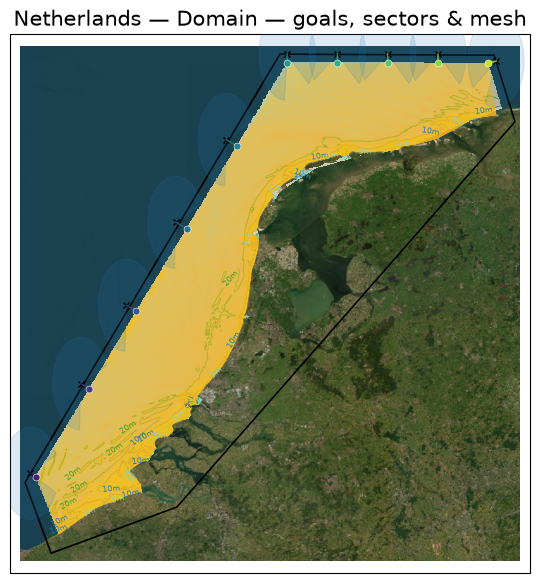

saved -> /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/gui_figures/fig01_domain.png


PosixPath('/lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/gui_figures/fig01_domain.png')

In [3]:
apply_slide_style()
goal_ids = sorted(int(k) for k in goals)
colors = goal_colors(goal_ids)

fig, ax = cp.plot_base_map(
    title="Domain — goals, sectors & mesh",
    show_satellite=True,
    show_topobathy=True,
    show_isobaths=True,
    show_aoi=True,
)
cp.plot_mesh("inputs/GRID/Netherlands_mesh.nc", ax)
cp.plot_sectors(targets, goals, boundary_snaps, ax, radius_deg=0.28)

for gid in goal_ids:
    key = str(gid)
    snap = boundary_snaps[key]
    hc = goals[key]["hindcast"]["whacs"]
    color = colors[gid]
    ax.plot(
        [snap["longitude"], hc["longitude"]],
        [snap["latitude"], hc["latitude"]],
        color=color,
        linewidth=1.2,
        alpha=0.75,
        zorder=5,
    )
    ax.plot(
        hc["longitude"],
        hc["latitude"],
        marker="o",
        color=color,
        markersize=5,
        markeredgecolor="white",
        markeredgewidth=0.4,
        zorder=6,
    )

x0, x1, y0, y1 = course_map_extent()
ax.set_xlim(x0, x1)
ax.set_ylim(y0, y1)

save_fig(fig, "fig01_domain")

## Fig 2 — Reconstruction comparison: dynamic vs. metamodel

Hs at every isobath + buoy site (`site_source` = isobath/buoy, ~3,900
points), comparing the full **dynamic** SnapWave hindcast against the
**metamodel** reconstruction, for a stormy moment and a calm moment (each
found within `comparison_period`, but only that single *day* is actually
reconstructed for each — same "restrict the time window" reasoning as
Fig 4's spectra network below: cost is dominated by per-goal model loading,
not by how many timesteps get reconstructed). Top row: storm peak. Bottom
row: lowest-Hs moment. Columns: dynamic, metamodel, difference
(metamodel - dynamic).

Uses the same reconstruction path validated in
`09_Validate_Linear_Summation.ipynb` (`mm.reconstruct` for the metamodel
side, the consolidated `Dynamic_Cases_WHACS_<comparison_period>.nc` for the
dynamic reference, `val.align_pair` for the shared-site alignment) — the
sites here just render as a colored scatter instead of a boxplot.


Storm peak: 2013-12-05 19:00:00  (reconstructing day 2013-12-05)
Calm moment: 2013-07-26 12:00:00  (reconstructing day 2013-07-26)


Machine   48 cores, 413 GiB free of 503 GiB, no GPU -> at most 36 cores, 310 GiB (75%)
Request   isobaths n=550 bulk (10 contributions/site), '2013-12-05': 4971 of 4971 site-months to compute, in 1 month(s)
Proposed  device cpu, 36 threads (GP + PCA), 36 workers (spectral sum), 1 month(s) x every site per call, 310 GiB
Per call  ~101 GiB of 310 GiB: contributions 2.2, spectra 0.0, spectral sum 99.0 (36 workers)
Time      ~2 min (rate measured on a 48-core Xeon Gold 5418Y node; yours may differ)
Spectra   not saved (save_spectra=True to keep them): ~30.9 GB on disk for these site-months, 16075 GB free
Edit the fields if wanted (res.workers = ...), then reconstruct(..., resources=res).


INFO:bluemath_tk.waves.hywaves.reconstruction:sum: 38 sites across 36 workers (2.00 GiB each)
INFO:bluemath_tk.waves.hywaves.reconstruction:[item 4/36] sum block 1/1 (1 sites x 744 steps) in 0.8s (0.8s elapsed)
INFO:bluemath_tk.waves.hywaves.reconstruction:[item 5/36] sum block 1/1 (1 sites x 744 steps) in 0.8s (0.9s elapsed)
INFO:bluemath_tk.waves.hywaves.reconstruction:[item 7/36] sum block 1/1 (1 sites x 744 steps) in 0.8s (0.8s elapsed)
INFO:bluemath_tk.waves.hywaves.reconstruction:[item 6/36] sum block 1/1 (1 sites x 744 steps) in 0.8s (0.8s elapsed)
INFO:bluemath_tk.waves.hywaves.reconstruction:[item 3/36] sum block 1/1 (1 sites x 744 steps) in 0.8s (0.9s elapsed)
INFO:bluemath_tk.waves.hywaves.reconstruction:[item 8/36] sum block 1/1 (1 sites x 744 steps) in 0.8s (0.9s elapsed)
INFO:bluemath_tk.waves.hywaves.reconstruction:[item 9/36] sum block 1/1 (1 sites x 744 steps) in 0.8s (0.8s elapsed)
INFO:bluemath_tk.waves.hywaves.reconstruction:[item 2/36] sum block 1/1 (2 sites x 744 

Comparison sites: 5148 (isobath + buoy)


INFO:bluemath_tk.waves.hywaves.reconstruction:sum: 38 sites across 36 workers (2.00 GiB each)
INFO:bluemath_tk.waves.hywaves.reconstruction:[item 3/36] sum block 1/1 (1 sites x 744 steps) in 0.8s (0.8s elapsed)
INFO:bluemath_tk.waves.hywaves.reconstruction:[item 6/36] sum block 1/1 (1 sites x 744 steps) in 0.8s (0.8s elapsed)
INFO:bluemath_tk.waves.hywaves.reconstruction:[item 7/36] sum block 1/1 (1 sites x 744 steps) in 0.8s (0.8s elapsed)
INFO:bluemath_tk.waves.hywaves.reconstruction:[item 5/36] sum block 1/1 (1 sites x 744 steps) in 0.8s (0.9s elapsed)
INFO:bluemath_tk.waves.hywaves.reconstruction:[item 4/36] sum block 1/1 (1 sites x 744 steps) in 0.9s (0.9s elapsed)
INFO:bluemath_tk.waves.hywaves.reconstruction:[item 8/36] sum block 1/1 (1 sites x 744 steps) in 0.8s (0.9s elapsed)
INFO:bluemath_tk.waves.hywaves.reconstruction:[item 12/36] sum block 1/1 (1 sites x 744 steps) in 0.8s (0.8s elapsed)
INFO:bluemath_tk.waves.hywaves.reconstruction:[item 9/36] sum block 1/1 (1 sites x 744

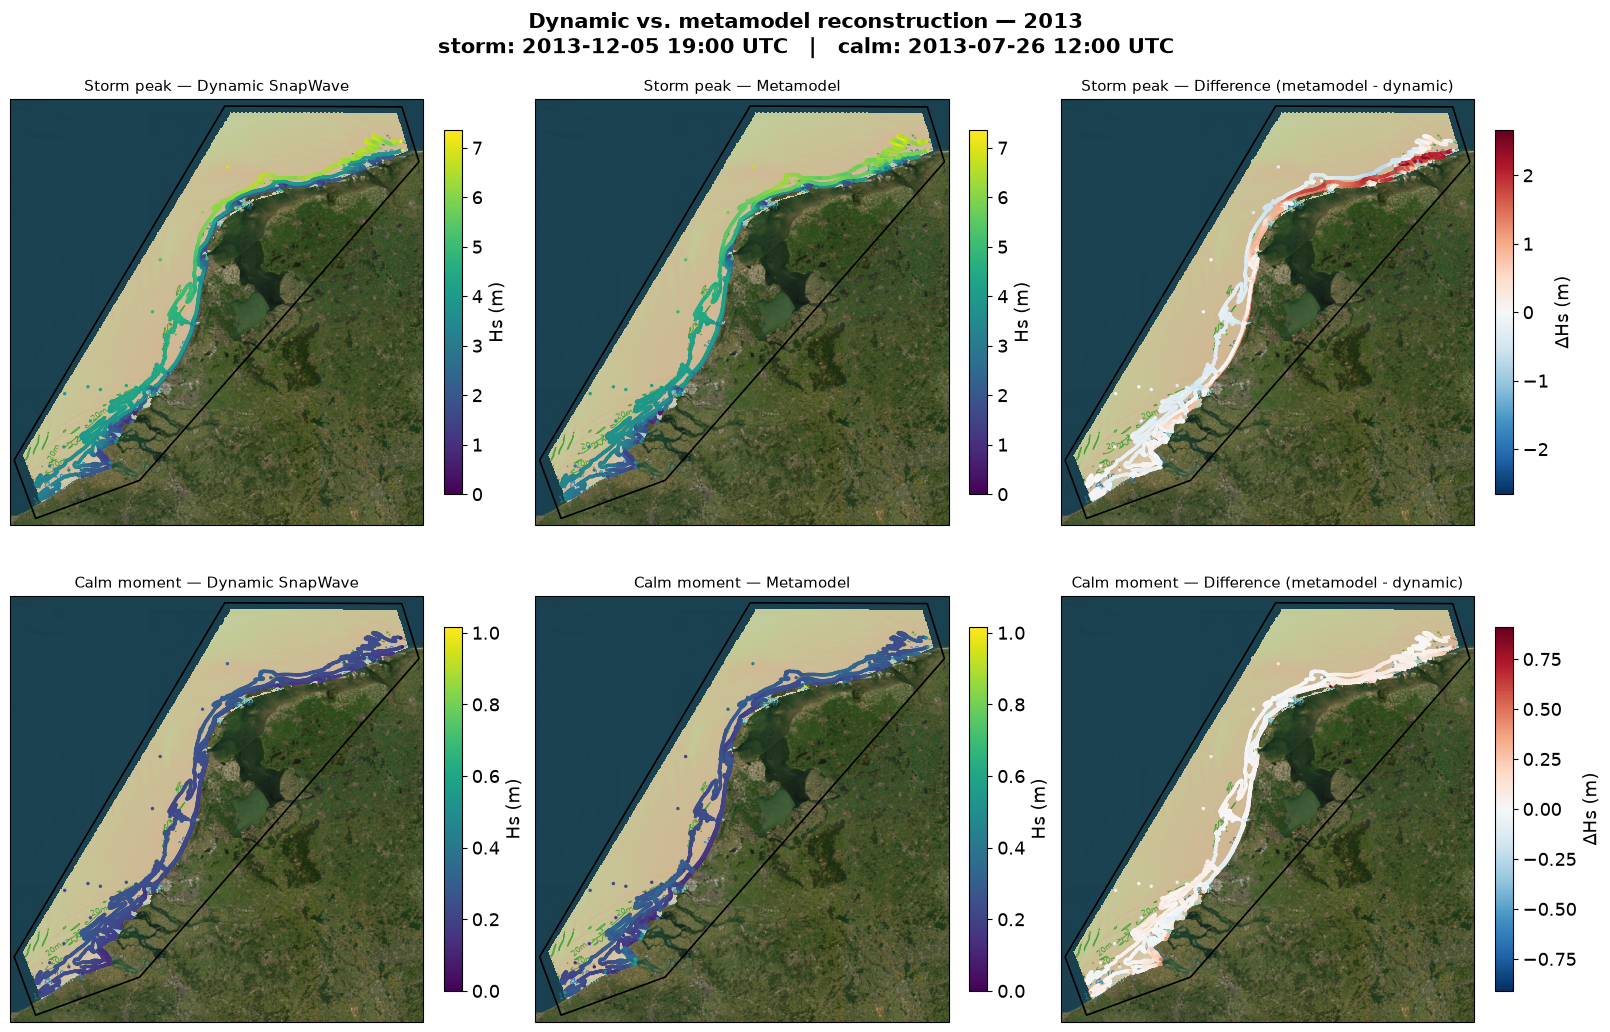

saved -> /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/gui_figures/fig02_map_comparison.png


PosixPath('/lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/gui_figures/fig02_map_comparison.png')

In [4]:
apply_slide_style()

storm_moment = pick_storm_peak_time(buoy_goal, period_=comparison_period)
calm_moment = pick_calm_time(buoy_goal, period_=comparison_period)
row_specs = [
    ("Storm peak", storm_moment, storm_moment.strftime("%Y-%m-%d")),
    ("Calm moment", calm_moment, calm_moment.strftime("%Y-%m-%d")),
]
for label, moment, day in row_specs:
    print(f"{label}: {moment}  (reconstructing day {day})")

# Same inner-join-on-shared-sites alignment 09_Validate_Linear_Summation.ipynb
# uses via val.compare() — reused directly rather than re-implementing it.
# Only the single day containing each moment is reconstructed (not the whole
# comparison_period) — same affordability reasoning as Fig 4's spectra
# network: per-goal model loading dominates the cost, not the number of
# reconstructed timesteps, so a 24-hour window keeps this a notebook-scale
# call instead of a batch job.
fig, axes = plt.subplots(
    2,
    3,
    figsize=(16.0, 10.5),
    constrained_layout=True,
    subplot_kw={"projection": ccrs.PlateCarree()},
)
lon = lat = None
# one day of every set; sized for the largest set
res = mm.reconstruction_resources(
    row_specs[0][2],
    mda_n,
    metamodel="isobaths",
    spectral=False,
    offshore_name=offshore_name,
    save_spectra=False,
)

for row, (row_label, moment, day) in enumerate(row_specs):
    # every metamodel set (isobaths + buoys), joined on the sites dimension
    metamodel_day = xr.concat(
        [
            mm.reconstruct(
                day,
                mda_n,
                metamodel=mm_set,
                spectral=False,
                offshore_name=offshore_name,
                sites=None,
                resources=res,
                save_spectra=False,
            )
            for mm_set in mm.SETS
        ],
        dim="sites",
    )
    dynamic_day = xr.open_dataset(dynamic_path).sel(time=day).load()
    dynamic_aligned, metamodel_aligned = val.align_pair(
        reference=dynamic_day, estimate=metamodel_day
    )
    if lon is None:
        lon = metamodel_aligned.site_longitude.values
        lat = metamodel_aligned.site_latitude.values
        print(f"Comparison sites: {metamodel_aligned.sizes['sites']} (isobath + buoy)")

    dyn_hs = dynamic_aligned["hs"].sel(time=moment, method="nearest").values
    meta_hs = metamodel_aligned["hs"].sel(time=moment, method="nearest").values
    diff = meta_hs - dyn_hs
    vmax = float(np.nanmax([dyn_hs, meta_hs]))
    diff_abs = float(np.nanmax(np.abs(diff))) or 1.0

    panels = [
        (dyn_hs, val.DYNAMIC_REFERENCE_LABEL, "viridis", 0.0, vmax),
        (meta_hs, "Metamodel", "viridis", 0.0, vmax),
        (diff, "Difference (metamodel - dynamic)", "RdBu_r", -diff_abs, diff_abs),
    ]
    for col, (values, title, cmap, vmin, vc) in enumerate(panels):
        ax = axes[row, col]
        cp.plot_base_map(
            ax=ax,
            title=None,
            show_satellite=True,
            show_topobathy=True,
            show_isobaths=True,
            show_aoi=True,
        )
        sc = ax.scatter(
            lon,
            lat,
            c=values,
            cmap=cmap,
            vmin=vmin,
            vmax=vc,
            s=6,
            linewidths=0,
            zorder=4,
        )
        fig.colorbar(sc, ax=ax, shrink=0.75, label="Hs (m)" if col < 2 else "ΔHs (m)")
        ax.set_title(f"{row_label} — {title}", fontsize=11)
        ax.set_xlabel("")
        ax.set_ylabel("")

fig.suptitle(
    f"Dynamic vs. metamodel reconstruction — {comparison_period}\n"
    f"storm: {storm_moment:%Y-%m-%d %H:%M} UTC   |   calm: {calm_moment:%Y-%m-%d %H:%M} UTC",
    fontsize=15,
    fontweight="bold",
)

save_fig(fig, "fig02_map_comparison")

## Fig 3 — Metamodel training (LHS cases)

Sampled wave directions per goal from the **500 LHS SnapWave cases** (notebook 05).
Reuses the same diagnostic layout as case generation.


LHS cases loaded: 6,290 rows across 10 goals


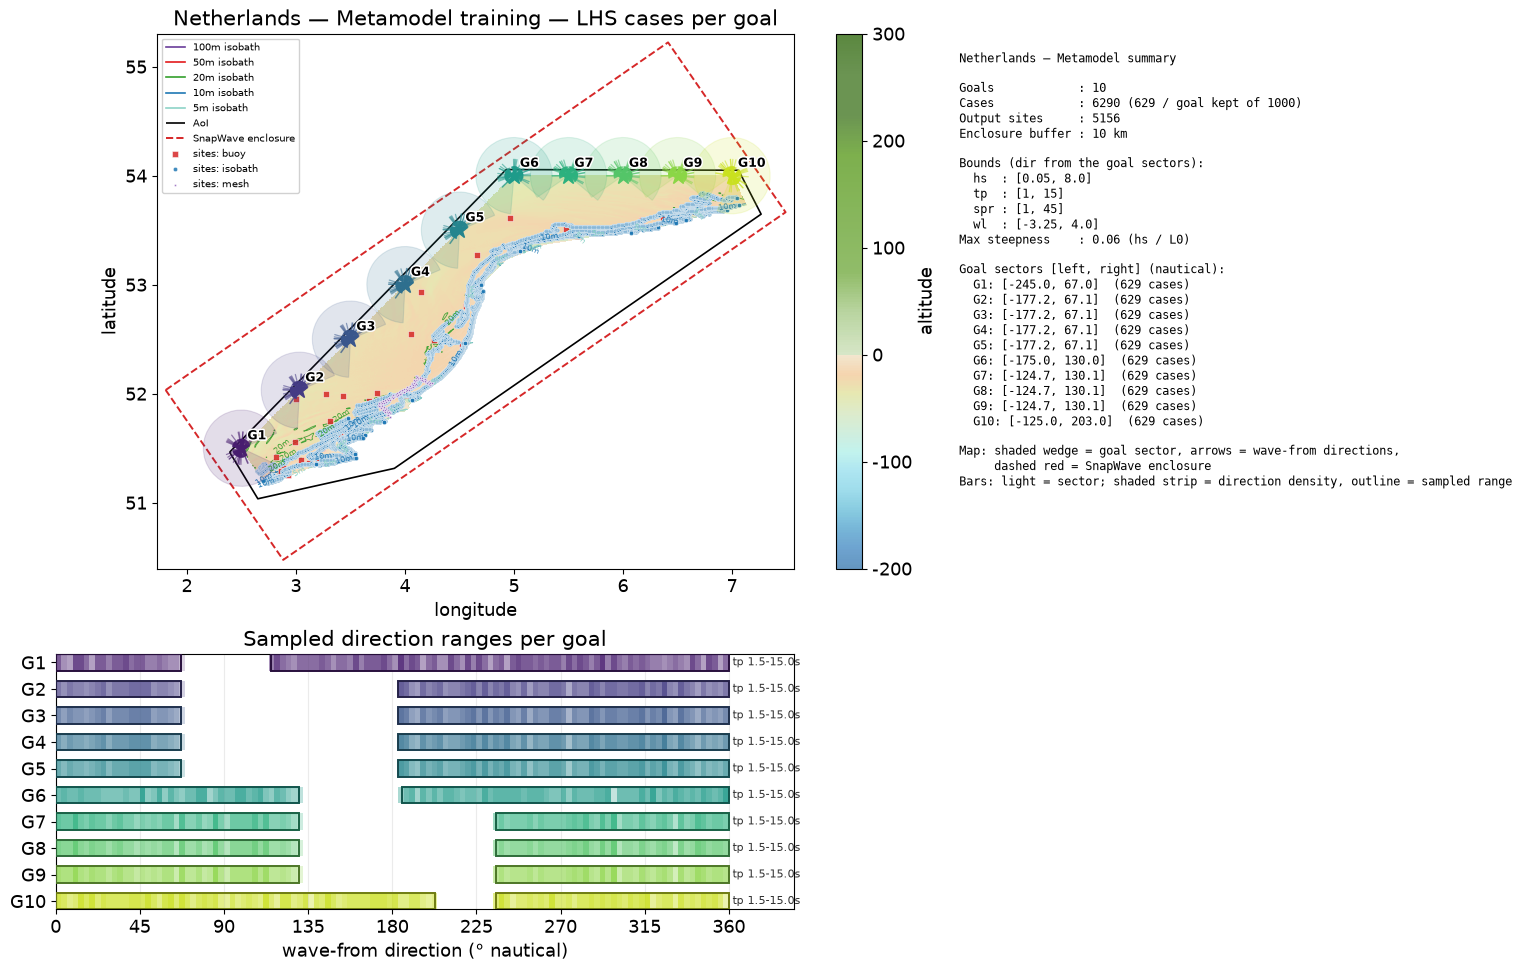

saved -> /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/gui_figures/fig03_metamodel.png


PosixPath('/lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/gui_figures/fig03_metamodel.png')

In [5]:
apply_slide_style()
lhs_cases = build_lhs_cases_df()
print(
    f"LHS cases loaded: {len(lhs_cases):,} rows across {lhs_cases['goal'].nunique()} goals"
)

fig = cp.plot_metamodel_configuration(
    model_boundary=model_boundary,
    model_boundary_label=model_boundary_label,
    goals_config=goals_config,
    cases_df=lhs_cases,
    output_sites_df=output_sites_df,
    bounds=SIMULATIONS.get("bounds"),
    num_samples_per_goal=SIMULATIONS.get("num_samples_per_goal"),
    max_steepness=SIMULATIONS.get("max_steepness"),
    mesh_file=PATHS.get("mesh_file"),
    enclosure_buffer_m=case_setup.model_enclosure_buffer_m,
    show_topobathy=True,
    title="Metamodel training — LHS cases per goal",
)
save_fig(fig, "fig03_metamodel")

## Fig 4 — Reconstruction spectra network

Reconstructed **spectra bubbles** stamped directly onto the map at ~25
well-spaced sites along the 5 m isobath, together with the same WHACS
partition **forcing arrows** at the goals — one figure showing input
(arrows) and output (spectra spread across the whole domain) at the same
moment.

Only a single day (24 hours, containing `moment`) is reconstructed for these
sites — the cost here is dominated by per-goal model loading, not by the
number of days, so restricting the time window is what keeps this affordable.
The site list itself is spaced to ~25 points precisely so the bubbles stay
legible instead of overlapping (reconstructing all ~1,400 5 m-isobath sites
at once was tried and is impractically slow for a notebook figure).

**Budget ~3-5 minutes the first time** this cell runs (one fresh
`mm.reconstruct(spectral=True, ...)` call); cached after that via
`tmp/reconstruct/`.


In [6]:
forcing_moment = "2013-12-06 08:00"
resolve_forcing_moment()

Timestamp('2013-12-06 08:00:00')

2026-10-16 11:53:01,565 - hywaves.metamodel - WARNING - Dropped 5 site(s) not in set 'isobaths' or removed by the site filter: 5m_738, 5m_739, 5m_1051, 5m_1058, 5m_1089


Spectra network moment: 2013-12-06 08:00:00  (reconstructing day 2013-12-06)
Spectra network sites: 11 (of 1170 on 5 m isobath)
Machine   48 cores, 411 GiB free of 503 GiB, no GPU -> at most 36 cores, 308 GiB (75%)
Request   isobaths n=550 spectral (40 contributions/site), '2013-12-06': 0 of 11 site-months to compute, in 0 month(s)
Proposed  device cpu, 36 threads (GP + PCA), 36 workers (spectral sum), 1 month(s) x every site per call, 308 GiB
Spectra   saved: ~0.0 GB on disk for these site-months, 16055 GB free
Edit the fields if wanted (res.workers = ...), then reconstruct(..., resources=res).


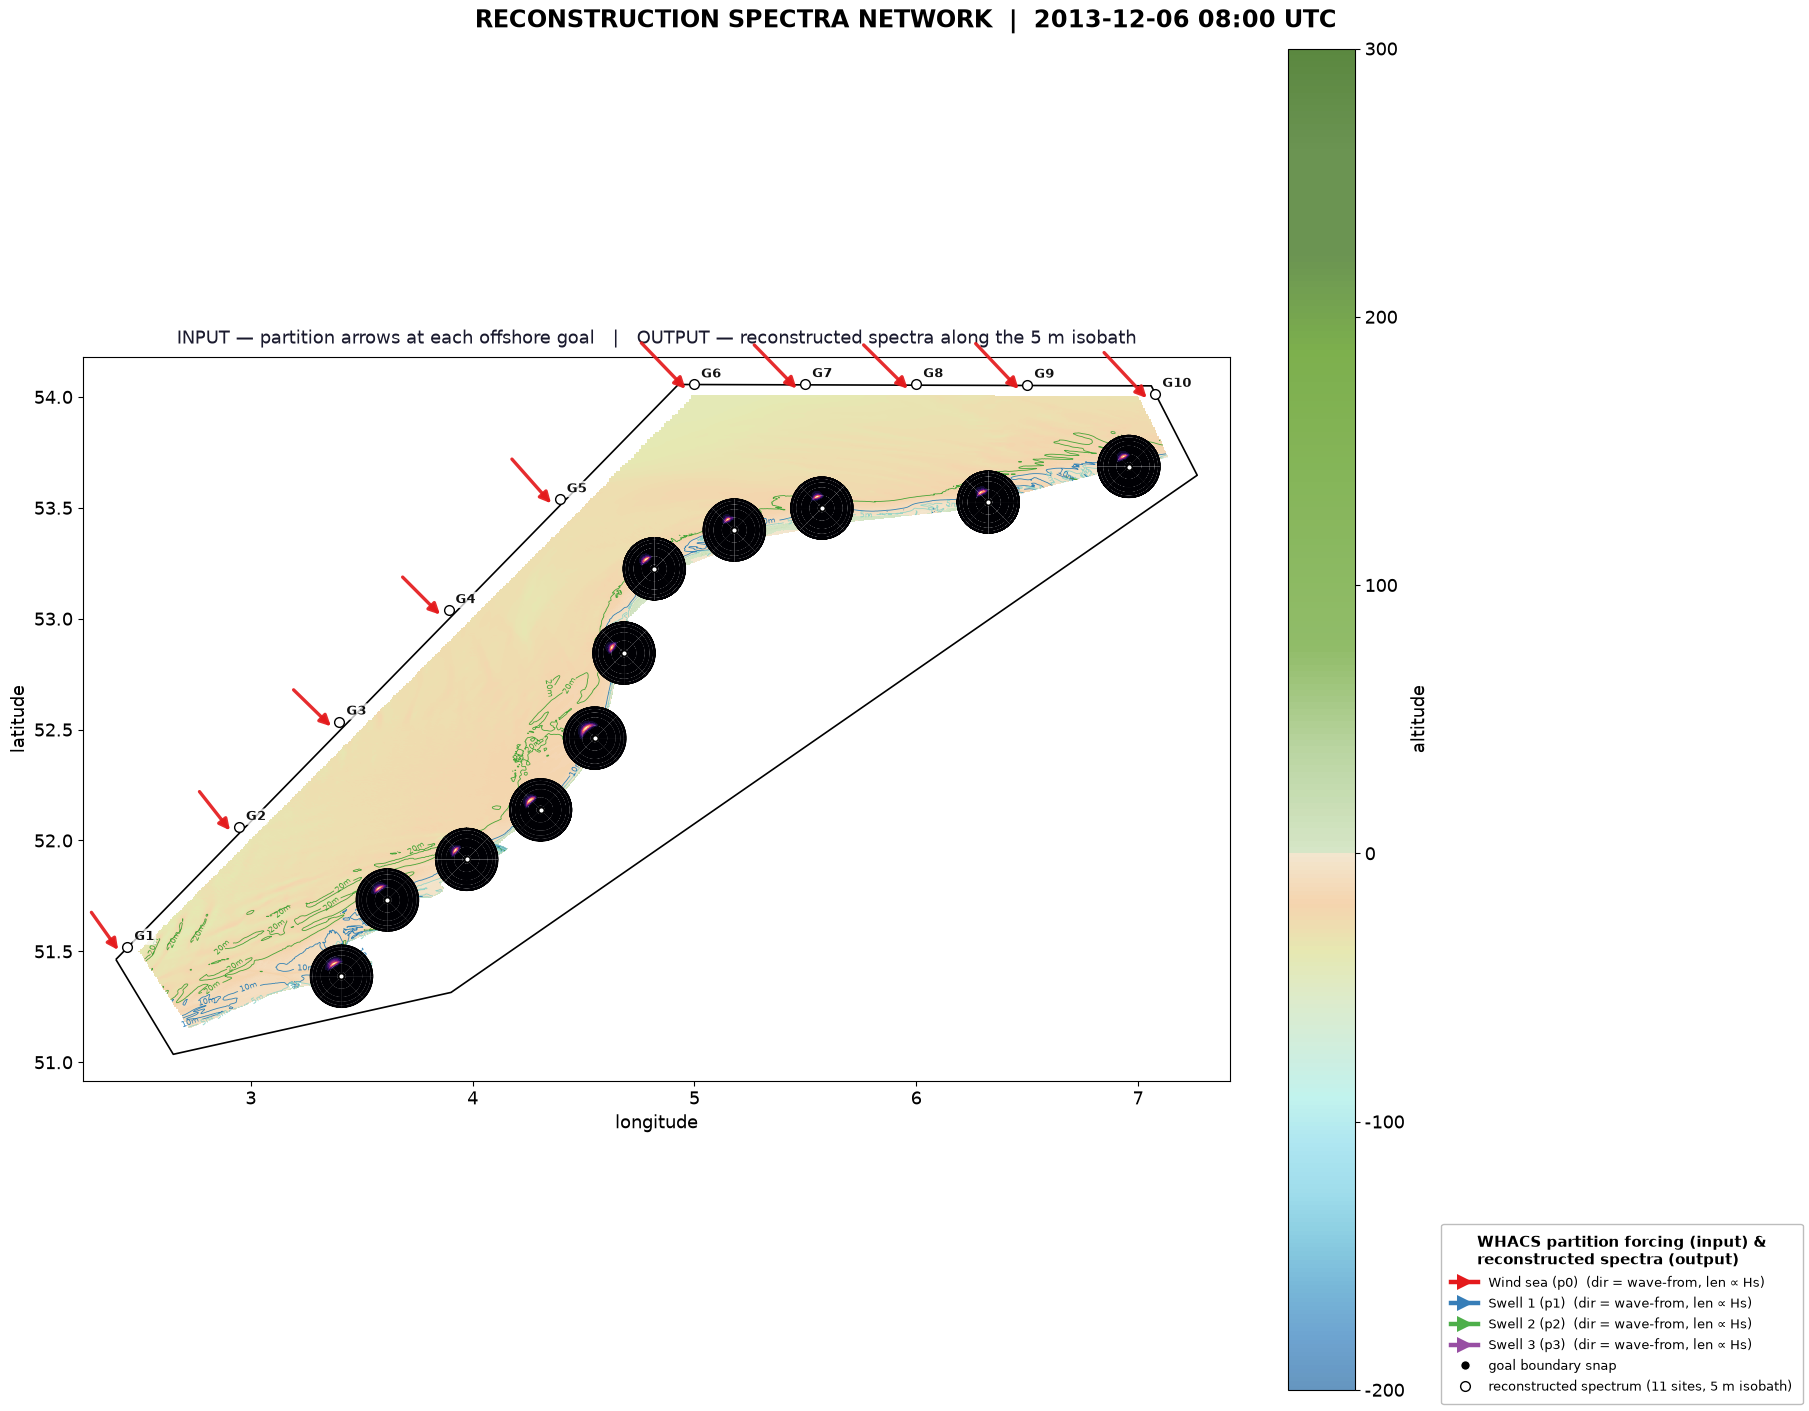

saved -> /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/gui_figures/fig04_spectra_reconstruction.png


PosixPath('/lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/gui_figures/fig04_spectra_reconstruction.png')

In [15]:
apply_slide_style()
moment = resolve_forcing_moment()
day = moment.strftime("%Y-%m-%d")
print(f"Spectra network moment: {moment}  (reconstructing day {day})")


def pick_spaced_sites(
    lons: np.ndarray, lats: np.ndarray, min_spacing_deg: float
) -> np.ndarray:
    """Greedy latitude-ordered subsample keeping a minimum on-map spacing.

    Checked against *every* previously kept point (not just the last one),
    since NSW's isobath sites zigzag enough in longitude that a simple
    running-neighbour check lets clusters of near-duplicate points through.
    """
    order = np.argsort(lats)[::-1]  # north to south, matches G1..G26
    picked: list[int] = []
    pts: list[np.ndarray] = []
    for idx in order:
        pt = np.array([lons[idx], lats[idx]])
        if not pts or all(np.hypot(*(pt - p)) >= min_spacing_deg for p in pts):
            picked.append(idx)
            pts.append(pt)
    return np.array(picked)


common_5m = mm.reconstruction_sites("isobaths", "5m")
meta_5m = site_meta(common_5m)
lon_5m = meta_5m.site_longitude.values
lat_5m = meta_5m.site_latitude.values

keep = pick_spaced_sites(lon_5m, lat_5m, min_spacing_deg=0.4)
network_site_ids = [common_5m[i] for i in keep]
print(
    f"Spectra network sites: {len(network_site_ids)} (of {len(common_5m)} on 5 m isobath)"
)

network_kw = dict(
    n=mda_n,
    metamodel="isobaths",  # metamodel set fitted on the isobath sites
    offshore_name=offshore_name,
    goals=None,
    wl=wl,
)

res = mm.reconstruction_resources(
    day, spectral=True, sites=network_site_ids, save_spectra=True, **network_kw
)
mm.reconstruct(
    day,
    spectral=True,
    sites=network_site_ids,
    save_spectra=True,
    resources=res,
    **network_kw,
)
network_spec = mm.load_reconstruction_spectra(
    day, spectral=True, sites=network_site_ids, **network_kw
)
network_efth = network_spec["efth"].sel(time=moment, method="nearest")

fig, ax = plt.subplots(figsize=(18.0, 14.0), constrained_layout=True)
cp.plot_base_map(ax=ax, title=None, show_topobathy=True)
draw_goal_partition_arrows(ax, moment)

for site_id in network_site_ids:
    da = network_efth.sel(sites=site_id)
    if not np.isfinite(da.values).any() or float(da.max()) <= 0:
        continue
    lon = float(meta_5m.site_longitude.sel(sites=site_id))
    lat = float(meta_5m.site_latitude.sel(sites=site_id))
    img = render_spectrum_bubble(da, figsize=(1.9, 1.9))
    ax.plot(
        lon, lat, "o", color="white", markeredgecolor="black", markersize=4, zorder=7
    )
    ax.add_artist(
        AnnotationBbox(
            OffsetImage(np.asarray(img), zoom=0.24),
            (lon, lat),
            frameon=False,
            pad=0,
            zorder=6,
        )
    )

x0, x1, y0, y1 = course_map_extent()
ax.set_xlim(x0, x1)
ax.set_ylim(y0, y1)
ax.set_aspect("equal", adjustable="box")
# plot_base_map(title=None) falls back to a default "Case map" title rather
# than omitting one - overwrite it here.
ax.set_title(
    "INPUT — partition arrows at each offshore goal   |   "
    "OUTPUT — reconstructed spectra along the 5 m isobath",
    fontsize=13,
    pad=10,
    color="#1a1a2e",
)

legend_handles = partition_legend_handles() + [
    plt.Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor="white",
        markeredgecolor="black",
        markersize=7,
        linestyle="None",
        label=f"reconstructed spectrum ({len(network_site_ids)} sites, 5 m isobath)",
    )
]
leg = fig.legend(
    handles=legend_handles,
    loc="outside right lower",
    fontsize=9.5,
    framealpha=0.96,
    edgecolor="#bbbbbb",
    title="WHACS partition forcing (input) &\nreconstructed spectra (output)",
    title_fontsize=10.5,
    ncol=1,
    borderpad=0.8,
)
leg.get_title().set_fontweight("bold")

fig.suptitle(
    f"RECONSTRUCTION SPECTRA NETWORK  |  {moment:%Y-%m-%d %H:%M} UTC",
    fontsize=17,
    fontweight="bold",
)

save_fig(fig, "fig04_spectra_reconstruction")

## Export summary


In [16]:
sorted(EXPORT_DIR.glob("fig*.png"))

[PosixPath('/lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/gui_figures/fig01_domain.png'),
 PosixPath('/lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/gui_figures/fig02_map_comparison.png'),
 PosixPath('/lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/gui_figures/fig03_metamodel.png'),
 PosixPath('/lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/gui_figures/fig04_spectra_reconstruction.png')]